# Forecasting health, objective and action advantage at +1 and +16

The capture-disjoint E242 test compares the four forecast heads. A separate archived Phase 1.2
replay checks direct objective advantage versus composing loss and RankMe with the original O3 scales.

**Readout:** The hybrid gave the lowest raw ΔJ error on the O3-style objective at both horizons.
At +16 it improved on the direct objective model by about 6% in RMSE. Direct advantage made the
lowest-regret decisions at +16 in both objective definitions. At +1 it always chose Skip.
The +16 semantic intervals include zero across all four predictors.

## Capture-disjoint E242 test

Fit on 132 development states from 36 BDD captures and tested on the registered Windows holdout
of 16 different captures, all from MAE seed 2026. Held-out outcomes and semantic labels stay outside fitting.
The Stage A and Windows development captures receive equal weight per capture. The same 26
pre-action state features and action identity feed the 48/24-unit MLP in every arm. The reported
prediction averages three training initializations. Each action set has six candidates at +1 and
eight at +16, including learning-rate, Skip and replay actions.

- **A** predicts 14 endpoint health changes across the new and historical banks. These include
  reconstruction loss, effective rank, spread, RMS correlation, CKA and retrieval measures.
  The registered objective is computed from the predicted endpoint.
- **B** predicts objective change from the common pre-action state.
- **C** predicts objective advantage relative to the fixed incoming-only 0.5× action. Its reference
  prediction is anchored at zero. This gives it a distinct target and leaves raw change unidentified.
- **D** uses the same forecast trunk with separate health and objective heads. Each normalized head has
  weight 1 in the loss, with no consistency penalty. Its direct objective determines the main
  choice. The auxiliary health readout is also evaluated through the same recomposition as A.

The O3-style objective uses new-bank loss and RankMe plus development-locked scales. The registered
E242 reward uses both banks, retrieval, spectral and CKA safeguards, and a known compute charge.
Higher objective is better in the E242 tests. Pairwise accuracy excludes measured ties within 0.01
objective units. Regret is the realized objective gap from the best action on each independent draw.
Semantic scores come from separate labeled probes on the chosen branch. Intervals resample the 16
held-out captures, with masks kept paired and the MAE seed and probe corpus held fixed.

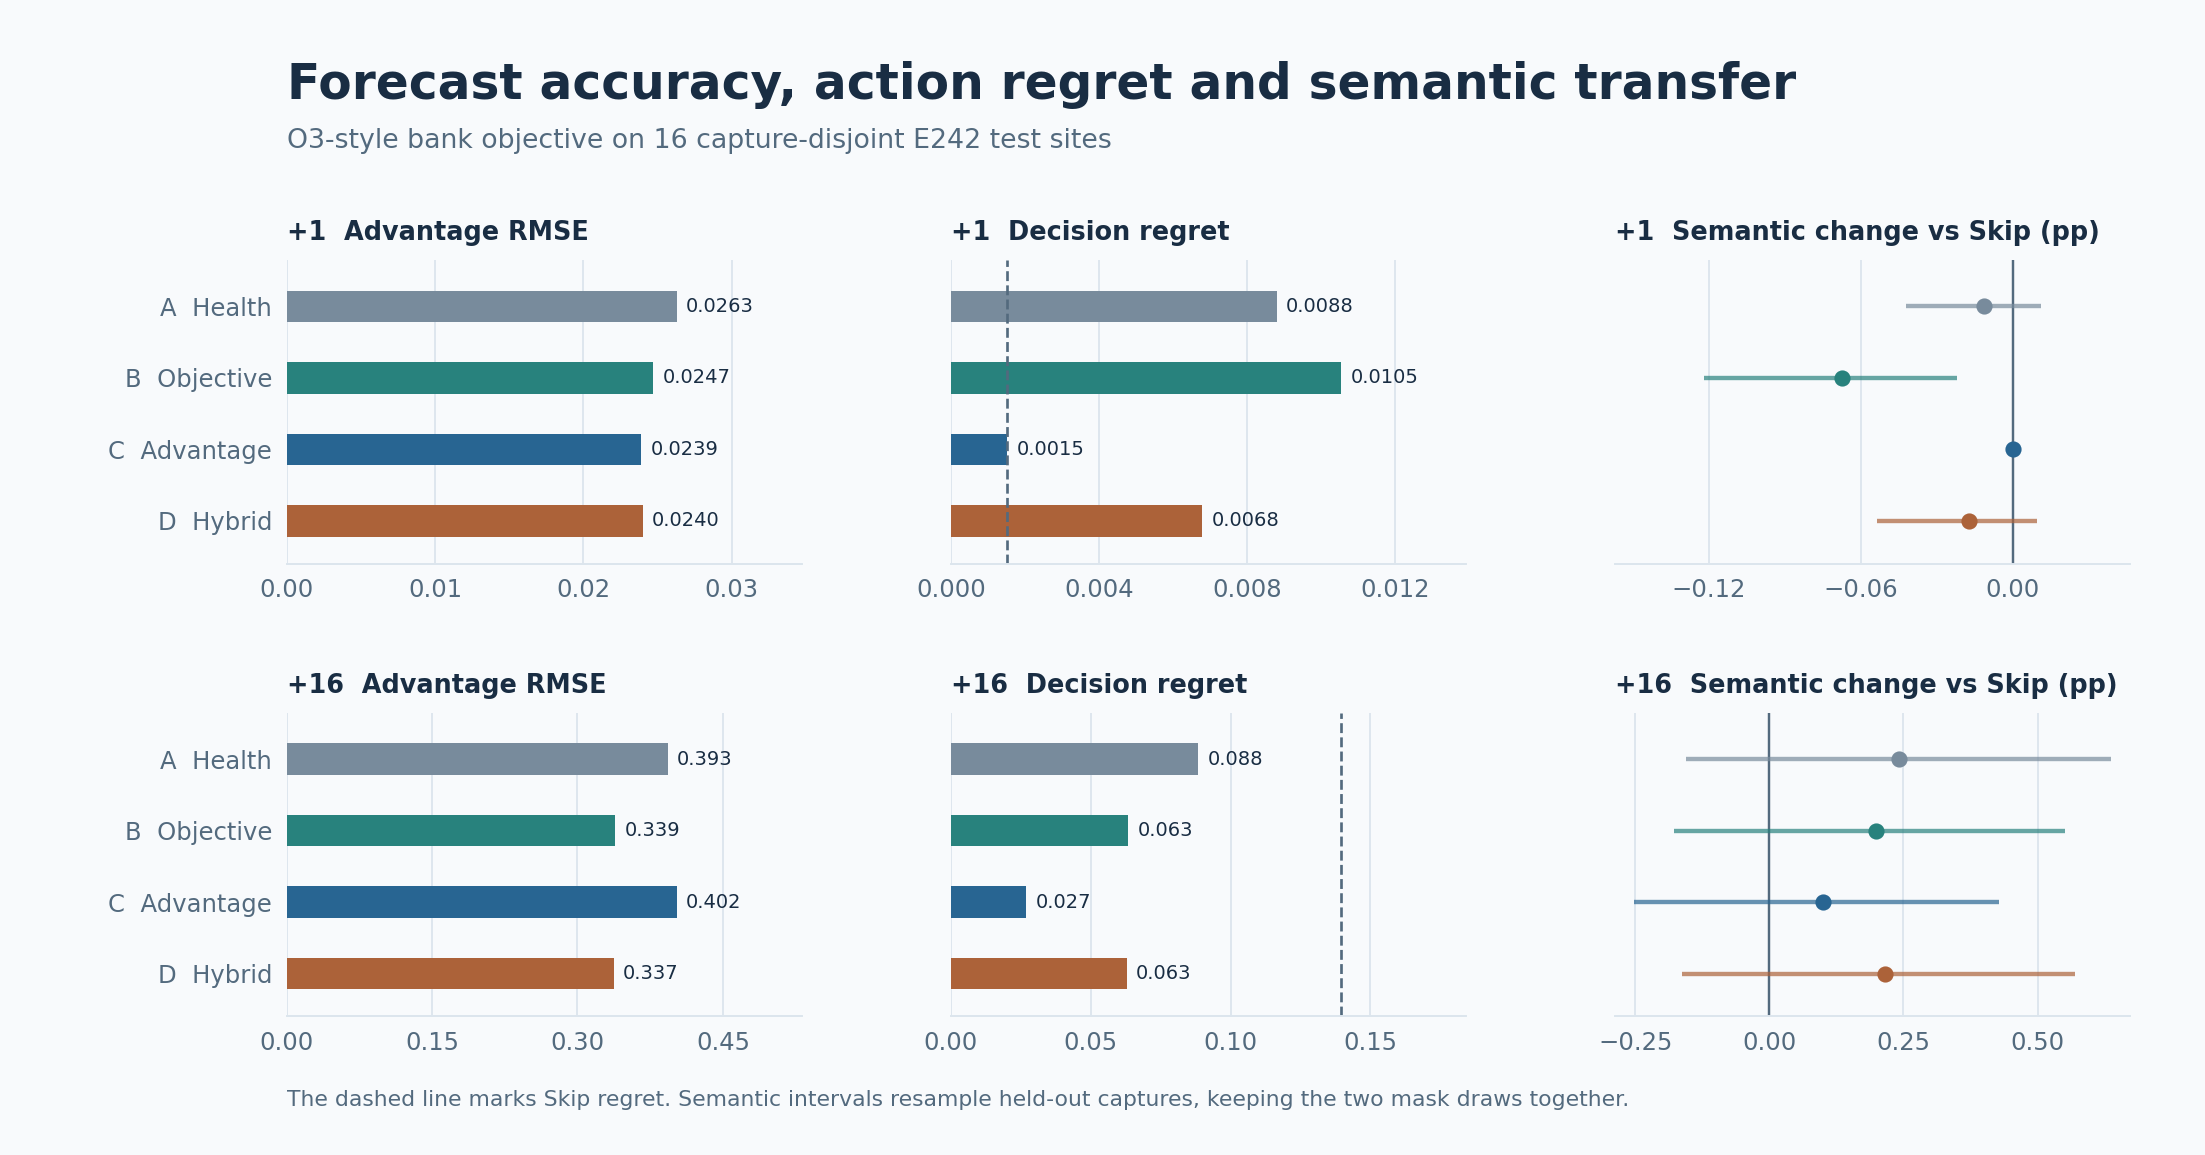

### O3-style bank objective

| Horizon | Model | ΔJ RMSE | Advantage RMSE | Pairwise accuracy | Regret | Semantic change vs Skip (95% interval) |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| +1 | A Health transitions | 0.0416 | 0.0263 | 71.3% | 0.0088 | -0.011 [-0.042, +0.011] pp |
| +1 | B Direct objective | 0.0395 | 0.0247 | 75.1% | 0.0105 | -0.068 [-0.122, -0.022] pp |
| +1 | C Direct advantage | — | 0.0239 | 78.4% | 0.0015 | +0.000 [+0.000, +0.000] pp |
| +1 | D Hybrid direct | 0.0390 | 0.0240 | 77.2% | 0.0068 | -0.017 [-0.054, +0.010] pp |
| +1 | D Hybrid health readout | 0.0400 | 0.0241 | 79.6% | 0.0027 | -0.010 [-0.044, +0.015] pp |
| +1 | Fixed Skip | — | — | — | 0.0015 | 0 pp |
| +16 | A Health transitions | 0.4358 | 0.3930 | 86.5% | 0.0885 | +0.241 [-0.155, +0.637] pp |
| +16 | B Direct objective | 0.4148 | 0.3388 | 89.3% | 0.0633 | +0.199 [-0.178, +0.551] pp |
| +16 | C Direct advantage | — | 0.4024 | 86.9% | 0.0270 | +0.101 [-0.252, +0.427] pp |
| +16 | D Hybrid direct | 0.3909 | 0.3374 | 90.8% | 0.0629 | +0.216 [-0.164, +0.570] pp |
| +16 | D Hybrid health readout | 0.4135 | 0.3439 | 91.2% | 0.0516 | +0.139 [-0.215, +0.465] pp |
| +16 | Fixed Skip | — | — | — | 0.1395 | 0 pp |

### Registered E242 reward

| Horizon | Model | ΔJ RMSE | Advantage RMSE | Pairwise accuracy | Regret | Semantic change vs Skip (95% interval) |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| +1 | A Health transitions | 0.6201 | 0.4208 | 83.7% | 0.0966 | -0.022 [-0.066, +0.000] pp |
| +1 | B Direct objective | 0.5910 | 0.3556 | 85.8% | 0.0964 | -0.033 [-0.088, +0.000] pp |
| +1 | C Direct advantage | — | 0.3489 | 84.4% | 0.0442 | +0.000 [+0.000, +0.000] pp |
| +1 | D Hybrid direct | 0.6492 | 0.3959 | 81.5% | 0.1531 | -0.037 [-0.095, +0.000] pp |
| +1 | D Hybrid health readout | 0.6459 | 0.3862 | 82.5% | 0.1008 | -0.015 [-0.044, +0.000] pp |
| +1 | Fixed Skip | — | — | — | 0.0442 | 0 pp |
| +16 | A Health transitions | 0.6167 | 0.5361 | 84.9% | 0.2135 | +0.063 [-0.261, +0.324] pp |
| +16 | B Direct objective | 0.6488 | 0.4868 | 87.1% | 0.1304 | +0.116 [-0.221, +0.436] pp |
| +16 | C Direct advantage | — | 0.5141 | 88.9% | 0.0643 | +0.029 [-0.294, +0.303] pp |
| +16 | D Hybrid direct | 0.6384 | 0.5156 | 86.9% | 0.1355 | +0.042 [-0.271, +0.306] pp |
| +16 | D Hybrid health readout | 0.6588 | 0.5041 | 86.8% | 0.1243 | +0.021 [-0.271, +0.273] pp |
| +16 | Fixed Skip | — | — | — | 0.2340 | 0 pp |

For the O3-style +16 target, the hybrid direct head reduced raw objective
RMSE from 0.4148 to 0.3909 relative to B and raised pairwise accuracy from 89.3% to 90.8%.
The paired capture-bootstrap interval for the relative RMSE reduction is [-7.0%, +13.0%].
Direct advantage achieved regret of 0.0270 compared with 0.0629 for the hybrid and 0.1395 for Skip.
The hybrid's semantic change was +0.217 pp versus Skip, with a capture-bootstrap interval of
−0.164 to +0.570 pp. Its advantage in pure forecast error depends on the objective definition.
On the registered E242 reward, B had lower raw error at +1 and A had lower raw error at +16.
These semantic estimates use independent probes on archived branches at the selected action.

## Original O3 replay

The two predictors use the same 88 inputs and calibration examples from seeds 2026–2028. Both
estimate advantages over Skip. One learns the scalar directly, and the other learns the two
component advantages before applying the original O3 weights. Each +16 branch holds the
15 subsequent quarter-rate updates fixed. The replay scores 128 audit origins per seed on the first
2,048 post-calibration arrivals. The online predictors update only after the paired targets mature.
Lower O3 cost is better in this replay. Predictions are scored on shared archived learner states.

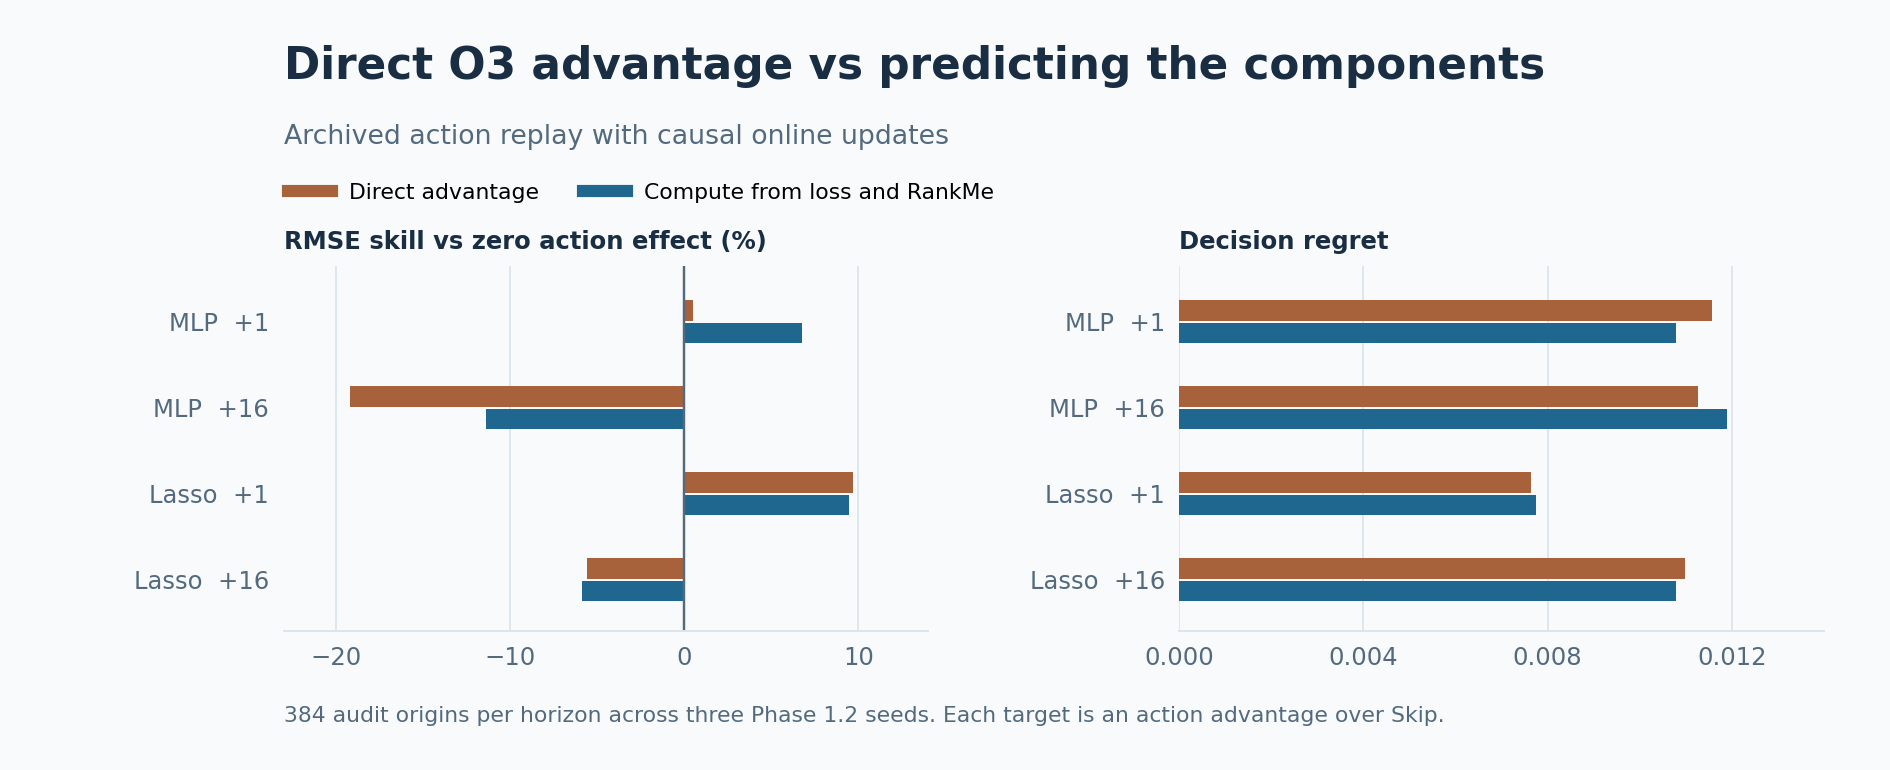

| Model | Horizon | Updates | Target | O3 RMSE | Skill vs zero | Pairwise accuracy | Regret |
| --- | --- | --- | --- | ---: | ---: | ---: | ---: |
| MLP | +1 | Frozen | direct | 0.04063 | +4.36% | 75.4% | 0.00860 |
| MLP | +1 | Frozen | composed | 0.03904 | +8.09% | 74.9% | 0.00881 |
| MLP | +1 | Online | direct | 0.04227 | +0.49% | 69.2% | 0.01157 |
| MLP | +1 | Online | composed | 0.03961 | +6.77% | 72.1% | 0.01078 |
| MLP | +16 | Frozen | direct | 0.03055 | -10.10% | 52.1% | 0.01197 |
| MLP | +16 | Frozen | composed | 0.02949 | -6.30% | 51.2% | 0.01194 |
| MLP | +16 | Online | direct | 0.03307 | -19.18% | 50.5% | 0.01126 |
| MLP | +16 | Online | composed | 0.03090 | -11.38% | 51.4% | 0.01189 |
| Lasso | +1 | Frozen | direct | 0.03779 | +11.04% | 77.0% | 0.00768 |
| Lasso | +1 | Frozen | composed | 0.03816 | +10.17% | 77.2% | 0.00766 |
| Lasso | +1 | Online | direct | 0.03836 | +9.69% | 76.2% | 0.00763 |
| Lasso | +1 | Online | composed | 0.03845 | +9.49% | 76.1% | 0.00775 |
| Lasso | +16 | Frozen | direct | 0.02839 | -2.34% | 51.0% | 0.01184 |
| Lasso | +16 | Frozen | composed | 0.02847 | -2.62% | 49.5% | 0.01187 |
| Lasso | +16 | Online | direct | 0.02929 | -5.58% | 53.5% | 0.01099 |
| Lasso | +16 | Online | composed | 0.02937 | -5.85% | 53.6% | 0.01079 |

For ridge with the same features and regularization, fitting a fixed linear
combination of outcomes commutes with fitting the components separately. The maximum observed
forecast difference was 3.28e-15. With MLPs the composed forecast had lower RMSE at both
horizons. Online Lasso changed little when trained directly. All online +16 variants scored below
the zero-action-effect forecast.

## Source records

[E242 runner](../../../../../analysis/2026-11-09-one-step-mpc/mae-e242-health-control/compare_forecast_heads.py) and
[held-out predictions](../../../../../analysis/2026-11-09-one-step-mpc/mae-e242-health-control/forecast-head-comparison/results.json).
[Original O3 replay runner](../../../../../analysis/2026-11-09-one-step-mpc/mae-p12-online16/run_direct_o3_targets.py) and
[matched rollout labels and predictions](../../../../../analysis/2026-11-09-one-step-mpc/mae-p12-online16/direct-o3-targets/pilot-2048/).